In [2]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)


In [4]:
# 2. Load the dataset
df = pd.read_csv("/kaggle/input/datasets/nabinpaude/placement/placement1.csv")

# Keep the required columns and remove incomplete rows
df = df[["cgpa", "package"]].dropna()

print(df.head())
print("Dataset shape:", df.shape)

   cgpa  package
0  6.89     3.26
1  5.12     1.98
2  7.82     3.25
3  7.42     3.67
4  6.94     3.57
Dataset shape: (200, 2)


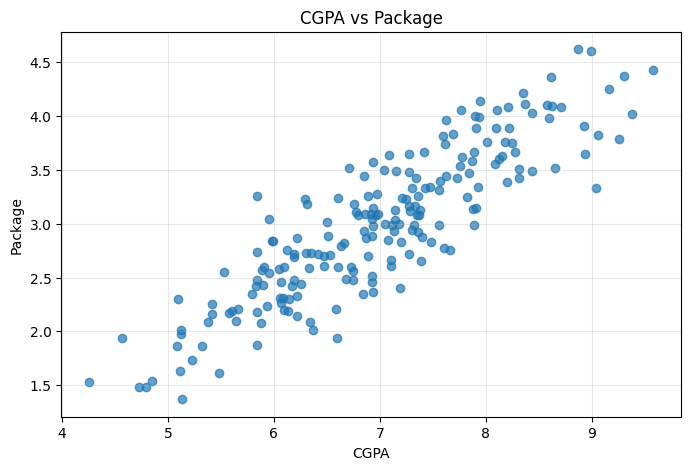

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(df["cgpa"], df["package"], alpha=0.7)
plt.xlabel("CGPA")
plt.ylabel("Package")
plt.title("CGPA vs Package")
plt.grid(alpha=0.3)
plt.show()


In [6]:
X = df[["cgpa"]]
y = df["package"]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [8]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [9]:
print("Slope:", lr.coef_[0])
print("Intercept:", lr.intercept_)
print(
    f"Regression equation: "
    f"Package = {lr.intercept_:.3f} "
    f"+ ({lr.coef_[0]:.3f} × CGPA)"
)

Slope: 0.5742564727019197
Intercept: -1.0270069374542108
Regression equation: Package = -1.027 + (0.574 × CGPA)


In [10]:
# 9. Evaluate the model on test data
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nTest-set evaluation")
print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")



Test-set evaluation
MAE:  0.232
MSE:  0.084
RMSE: 0.290
R²:   0.773


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


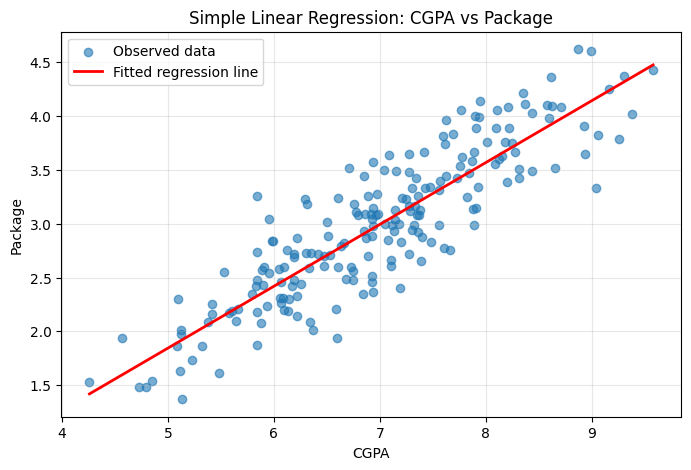

In [11]:
x_line = np.linspace(
    X["cgpa"].min(),
    X["cgpa"].max(),
    100
).reshape(-1, 1)

y_line = lr.predict(x_line)

plt.figure(figsize=(8, 5))
plt.scatter(
    X["cgpa"], y,
    alpha=0.6,
    label="Observed data"
)
plt.plot(
    x_line.ravel(),
    y_line,
    color="red",
    linewidth=2,
    label="Fitted regression line"
)
plt.xlabel("CGPA")
plt.ylabel("Package")
plt.title("Simple Linear Regression: CGPA vs Package")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
results = pd.DataFrame({
    "Actual Package": y_test.to_numpy(),
    "Predicted Package": y_pred
})

print(results.head(10))

   Actual Package  Predicted Package
0            2.79           2.780313
1            3.23           3.136352
2            3.26           3.199521
3            3.04           2.389819
4            3.34           3.526847
5            4.21           3.768035
6            2.94           3.165065
7            2.87           2.544868
8            2.99           3.176550
9            3.58           3.492392
